In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import IPython.display
import dataclasses
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors
import scipy.stats
import astropy.units as u
import astropy.visualization
import named_arrays as na
import optika
import iris
import ctis
import esis

In [3]:
velocity_max = 250 * u.km / u.s

In [4]:
%%time
scene = esis.flights.f1.data.synth.scene_iris(
    time_start="2014-07-04 11:40",
    velocity_max=velocity_max,
)

/opt/hostedtoolcache/Python/3.12.16/x64/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


CPU times: user 4min 18s, sys: 6.96 s, total: 4min 25s
Wall time: 35.2 s


In [5]:
scene.inputs.position = scene.inputs.position - scene.inputs.position.mean()

In [6]:
scene = scene[{scene.axis_time: 0}]
# the scene is already a radiance, so the mean exposure time of the raster
# steps can stand for all of them, which lets the scene be regridded and
# integrated over position
scene.timedelta = scene.timedelta[{scene.axis_time: 0}].mean(scene.axis_detector_x)

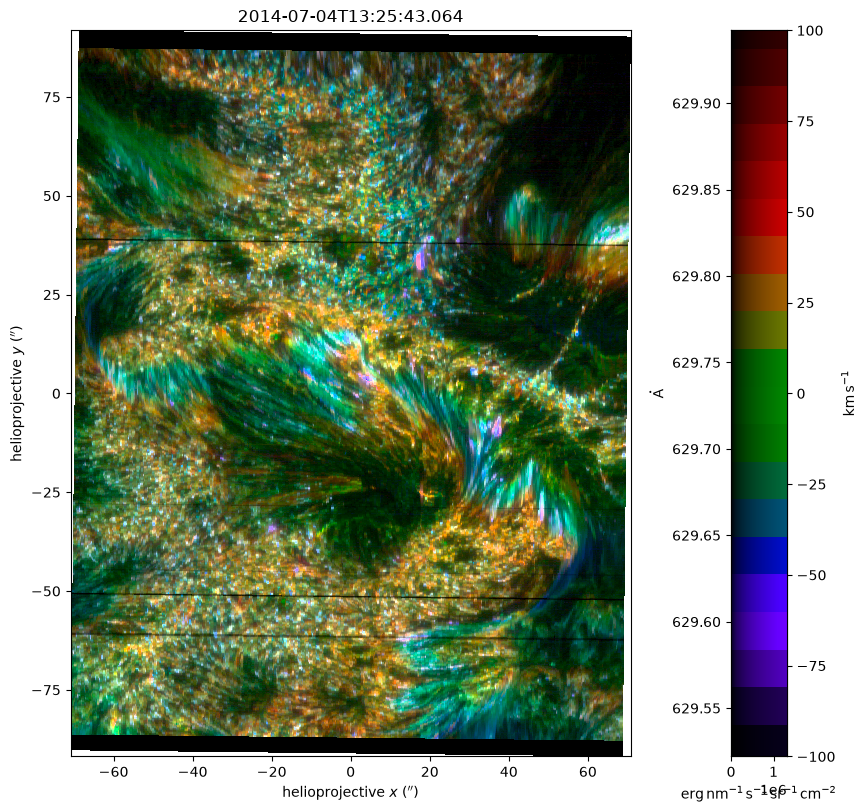

In [7]:
scene.show();

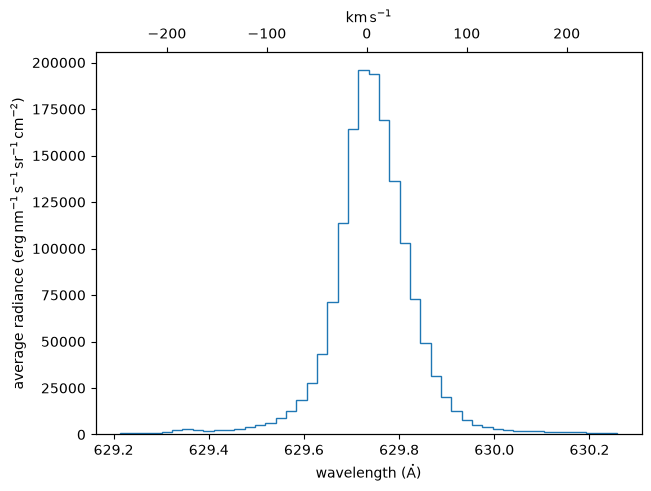

In [8]:
with astropy.visualization.quantity_support():
    fig, ax = plt.subplots(constrained_layout=True)
    ax_twin = ax.twiny()
    na.plt.stairs(
        scene.inputs.wavelength,
        scene.outputs.mean((scene.axis_detector_x, scene.axis_detector_y)),
        ax=ax,
        label="original",
        axis=scene.axis_wavelength,
    )
    na.plt.stairs(
        scene.inputs.velocity,
        scene.outputs.mean((scene.axis_detector_x, scene.axis_detector_y)),
        ax=ax_twin,
        label="original",
        axis=scene.axis_wavelength,
        linestyle="none",
    )
    ax.set_xlabel(f"wavelength ({ax.get_xlabel()})")
    ax.set_ylabel(f"average radiance ({ax.get_ylabel()})");

In [9]:
wavelength_rest = scene.inputs.wavelength_rest

In [10]:
# AA = dict(unit=u.AA, equivalencies=u.doppler_optical(wavelength_rest))

In [11]:
coordinates_scene = scene.inputs

In [12]:
# position_sensor = na.Cartesian2dVectorArray(
#     x=na.arange(0, 300 + 1, axis="sensor_x") * u.pix,
#     y=na.arange(0, 300 + 1, axis="sensor_y") * u.pix,
# )

In [13]:
# coordinates_sensor = na.SpectralPositionalVectorArray(
#     wavelength=scene.inputs.wavelength,
#     position=position_sensor,
# )

In [14]:
axis_channel = "channel"

In [15]:
# angle = na.linspace(0, 180, num=4, axis="channel", endpoint=False) * u.deg
# angle = angle + 0.4 * u.rad
# angle.ndarray

In [16]:
design = esis.flights.f1.optics.design(num_distribution=0)

In [17]:
design.wavelength = na.linspace(
    start=design.wavelength_min.mean(),
    stop=design.wavelength_max.mean(),
    axis="fit-wavelength",
    num=11,
)

In [18]:
channel = "Channel " + design.camera.channel.astype(str)

In [19]:
axis_channel = design.axis_channel

In [20]:
%%time
system_linear = design.system.linearize()

CPU times: user 3.53 s, sys: 195 ms, total: 3.72 s
Wall time: 1.7 s


In [21]:
scene.inputs.time.shape

{'detector_x': 401}

In [22]:
%%time
# image 8 velocity bins at a time, so that only their weights are in memory
images = system_linear.image(scene, chunk_size=8)

CPU times: user 2min 23s, sys: 14.5 s, total: 2min 38s
Wall time: 51 s


In [23]:
images = np.maximum(images, 0)

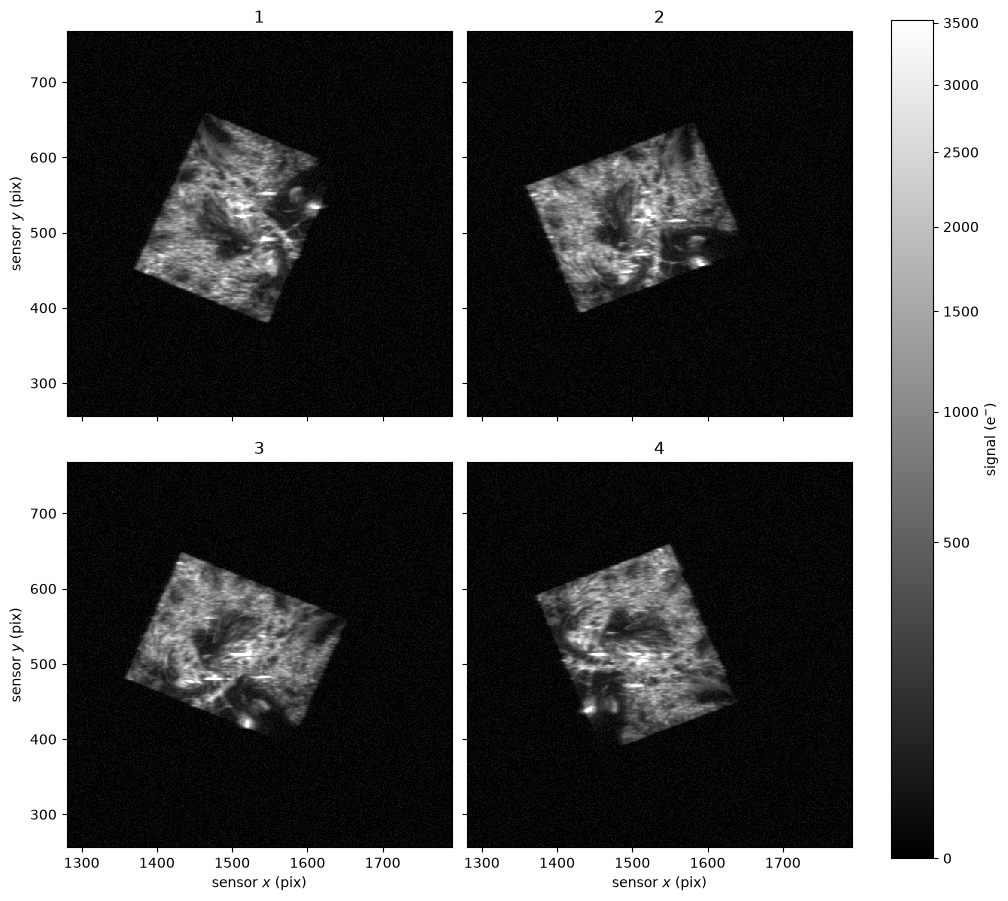

In [24]:
with astropy.visualization.quantity_support():
    fig, axs = na.plt.subplots(
        axis_rows="rows",
        axis_cols="cols",
        nrows=2,
        ncols=2,
        constrained_layout=True,
        figsize=(10,9),
        sharex=True,
        sharey=True,
        origin="upper",
    )
    ax = axs.combine_axes(("rows", "cols"), axis_channel)
    norm = matplotlib.colors.PowerNorm(
        gamma=0.5,
        vmin=0,
        # vmax=10,
        vmax=images.outputs.value.percentile(99.99).ndarray,
    )
    colorizer = plt.Colorizer(
        cmap="gray",
        norm=norm,
    )
    img = na.plt.pcolormesh(
        # channel,
        images.inputs.position.x,
        images.inputs.position.y,
        C=images.outputs.value,
        ax=ax,
        colorizer=colorizer,
    )
    plt.colorbar(
        mappable=plt.cm.ScalarMappable(colorizer=colorizer),
        ax=ax.ndarray,
        label=f"signal ({images.outputs.unit:latex_inline})",
    )
    na.plt.set_title(design.camera.channel, ax=ax)
    na.plt.set_aspect("equal", ax=ax)
    na.plt.set_xlabel(f"sensor $x$ ({images.inputs.position.x.unit})", ax=axs[dict(rows=~0)])
    na.plt.set_ylabel(f"sensor $y$ ({images.inputs.position.y.unit})", ax=axs[dict(cols=0)])
    na.plt.set_xlim(1024 + 256, 1024 + 512 + 256, ax=ax)
    na.plt.set_ylim(256, 512 + 256, ax=ax)

In [25]:
coefficients = system_linear.distortion.fit.coefficients

In [26]:
dispersion = 1 / coefficients.components["wavelength"].length.ndarray.mean() * u.pix
dispersion = (wavelength_rest + dispersion).to(u.km / u.s, equivalencies=u.doppler_optical(wavelength_rest)) / u.pix
dispersion

<Quantity 17.51654863 km / (pix s)>

In [27]:
plate_scale = 1 / coefficients.components["position.x"].length.ndarray.mean()
plate_scale = plate_scale.to(u.arcsec / u.pix)
plate_scale

<Quantity 0.75328572 arcsec / pix>

In [28]:
velocity_degraded = ctis.arange(
    start=-velocity_max,
    stop=+velocity_max,
    step=dispersion * u.pix,
    axis=scene.axis_wavelength,
)

In [29]:
position_degraded = ctis.arange(
    start=coordinates_scene.position.min(),
    stop=coordinates_scene.position.max(),
    step=plate_scale * u.pix,
    axis=na.Cartesian2dVectorArray(
        x=scene.axis_detector_x,
        y=scene.axis_detector_y,
    )
)

In [30]:
coordinates_degraded = na.TemporalDopplerPositionalVectorArray.from_velocity(
    time=scene.inputs.time.mean(scene.axis_detector_x),
    velocity=velocity_degraded,
    wavelength_rest=wavelength_rest,
    position=position_degraded,
)

In [31]:
scene_degraded = ctis.regrid(
    coordinates_input=scene.inputs,
    coordinates_output=coordinates_degraded,
    values_input=scene.outputs,
    axis_wavelength=scene.axis_wavelength,
    axis_position=(scene.axis_detector_x, scene.axis_detector_y),
)
scene_degraded = scene.replace(
    inputs=coordinates_degraded,
    outputs=scene_degraded,
)

<Axes: title={'center': '2014-07-04T13:25:43.064'}, xlabel='helioprojective $x$ ($\\mathrm{{}^{\\prime\\prime}}$)', ylabel='helioprojective $y$ ($\\mathrm{{}^{\\prime\\prime}}$)'>

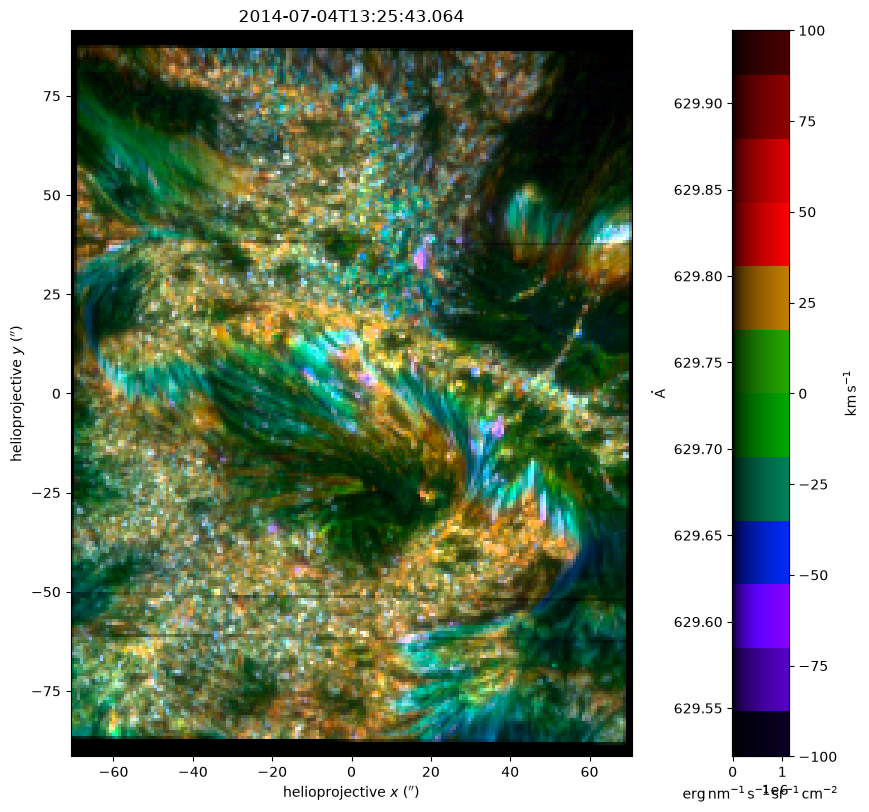

In [32]:
scene_degraded.show()

In [33]:
# %%time
# image_separated = instrument.image(scene, integrate=False, noise=False)

In [34]:
# %%time
# backprojected = instrument.backproject(image_separated, integrate=False)

In [35]:
# %%time
# scene_degraded = np.mean(backprojected, axis=axis_channel, keepdims=False)
# scene_degraded.shape

In [36]:
# scene_degraded = scene_degraded.replace(inputs=scene.inputs)

In [37]:
scene_degraded.outputs.mean()

ScalarArray(
    ndarray=31420.81036727 erg / (nm s sr cm2),
    shape={},
)

In [38]:
# backprojected.outputs.sum().to(scene.outputs.unit) / 4

In [39]:
coords_scene_single = coordinates_degraded.replace(wavelength=images.inputs.wavelength)
coords_sensor_single = images.inputs

In [40]:
images.inputs.wavelength

ScalarArray(
    ndarray=[629.21433364, 630.25752338] Angstrom,
    shape={'velocity': 2},
)

In [41]:
# design_monochromatic = dataclasses.replace(design, wavelength=images.inputs.wavelength)

In [42]:
# instrument_monochromatic = ctis.instruments.OptikaInstrument(
#     system=design_monochromatic.system.linearize(),
#     coordinates_scene=coordinates_scene,
#     channel=design.camera.channel,
#     axis_channel=design.axis_channel,
#     axis_wavelength=scene.axis_wavelength,
#     axis_scene_xy=(scene.axis_detector_x, scene.axis_detector_y),
# )

In [43]:
instrument = ctis.instruments.OptikaInstrument(
    system=system_linear,
    coordinates_scene=coordinates_degraded,
    channel=design.camera.channel,
    axis_channel=design.axis_channel,
    axis_wavelength=scene.axis_wavelength,
    axis_scene_xy=(scene.axis_detector_x, scene.axis_detector_y),
)

In [44]:
coordinates_single = coordinates_degraded.replace(wavelength=images.inputs.wavelength)

In [45]:
instrument_monochromatic = dataclasses.replace(
    instrument,
    coordinates_scene=coordinates_single,
)

In [46]:
%%time
backprojected_monochromatic = instrument_monochromatic.backproject(images, unit=scene.outputs.unit)

CPU times: user 4.66 s, sys: 156 ms, total: 4.81 s
Wall time: 4.15 s


In [47]:
min_monochromatic = np.min(backprojected_monochromatic, axis=axis_channel)[{axis_channel: 0}]

In [48]:
min_monochromatic.outputs.mean()

ScalarArray(
    ndarray=25658.71363584 erg / (nm s sr cm2),
    shape={},
)

In [49]:
backprojected = instrument.backproject(images, unit=scene.outputs.unit)

In [50]:
backprojected_monochromatic.outputs.sum()

ScalarArray(
    ndarray=5.66671802e+09 erg / (nm s sr cm2),
    shape={},
)

In [51]:
backprojected.outputs.sum()

ScalarArray(
    ndarray=1.58803173e+11 erg / (nm s sr cm2),
    shape={},
)

In [52]:
scene.outputs.mean()

ScalarArray(
    ndarray=31626.29040026 erg / (nm s sr cm2),
    shape={},
)

In [53]:
scene.integrate(axis=scene.axis_wavelength, component="wavelength").integrate(axis=(scene.axis_detector_x, scene.axis_detector_y), component="position").outputs.to(u.erg / u.s / u.cm**2)

ScalarArray(
    ndarray=0.00197304 erg / (s cm2),
    shape={},
)

In [54]:
scene_degraded.integrate(axis=scene.axis_wavelength, component="wavelength").integrate(axis=(scene.axis_detector_x, scene.axis_detector_y), component="position").outputs.to(u.erg / u.s / u.cm**2)

ScalarArray(
    ndarray=0.00197239 erg / (s cm2),
    shape={},
)

In [55]:
backprojected.integrate(axis=scene.axis_wavelength, component="wavelength").integrate(axis=(scene.axis_detector_x, scene.axis_detector_y), component="position").outputs.to(u.erg / u.s / u.cm**2)

ScalarArray(
    ndarray=[0.00194193, 0.00195395, 0.00195434, 0.0019429 ] erg / (s cm2),
    shape={'channel': 4},
)

In [56]:
min_monochromatic.outputs.shape

{'velocity': 1, 'detector_x': 188, 'detector_y': 243}

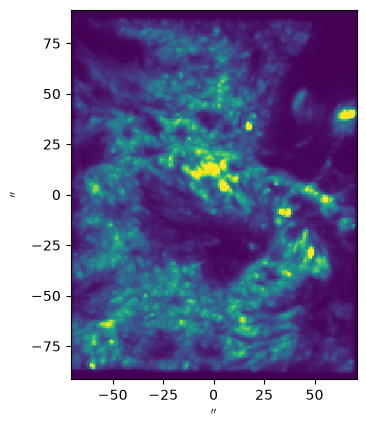

In [57]:
with astropy.visualization.quantity_support():
    fig, ax = plt.subplots()
    na.plt.pcolormesh(
        min_monochromatic.inputs.position.x,
        min_monochromatic.inputs.position.y,
        C=min_monochromatic.outputs.mean(scene.axis_wavelength).value,
        vmin=0,
        vmax=np.percentile(min_monochromatic.outputs, 99.5).value,
    )
    ax.set_aspect("equal")

In [58]:
mart = ctis.inverters.MartInverter(
    instrument=instrument,
    intermediate=True,
    num_iteration=50,
)

In [59]:
# spectrum_avg = scene.outputs.mean((scene.axis_detector_x, scene.axis_detector_y))
# spectrum_avg = spectrum_avg / spectrum_avg.sum()

In [60]:
std_OV = esis.flights.f1.spectrum.O_V.width_doppler
v = scene_degraded.inputs.velocity.cell_centers(scene.axis_wavelength)
# guess_spectral = np.exp(-np.square(v / std_OV) / 2)
std_OV = 37.5  * 1.5 * u.km / u.s
kappa = 0.2
v0 = 0 * u.km / u.s
guess_spectral = (1 + np.square((v - v0) / std_OV) / kappa)**(-kappa - 1)
guess_spectral = guess_spectral / guess_spectral.sum()

In [61]:
guess_spatial = backprojected_monochromatic.outputs.min(axis_channel)
# guess_spatial = guess_spatial.broadcast_to(scene.outputs.shape)
guess_spatial = guess_spatial / guess_spatial.sum()
guess_spatial.shape

{'velocity': 1, 'detector_x': 188, 'detector_y': 243}

In [62]:
guess_total = backprojected.outputs.sum().to(scene.outputs.unit) / 4
guess_total

ScalarArray(
    ndarray=3.97007933e+10 erg / (nm s sr cm2),
    shape={},
)

In [63]:
scene_degraded.outputs.sum()

ScalarArray(
    ndarray=4.01919924e+10 erg / (nm s sr cm2),
    shape={},
)

In [64]:
guess = guess_spectral * guess_spatial * guess_total
# guess = spectrum_avg * scene.outputs.sum()

In [65]:
guess = np.maximum(guess, 0)

In [66]:
guess.shape

{'velocity': 28, 'detector_x': 188, 'detector_y': 243}

In [67]:
guess_spectral.shape

{'velocity': 28}

In [68]:
scene.outputs.shape

{'detector_x': 400, 'detector_y': 1095, 'velocity': 48}

In [69]:
scene_degraded.shape

{'velocity': 28, 'detector_x': 188, 'detector_y': 243}

In [70]:
backprojected.shape

{'channel': 4, 'velocity': 28, 'detector_x': 188, 'detector_y': 243}

In [71]:
backprojected_monochromatic.shape

{'channel': 4, 'velocity': 1, 'detector_x': 188, 'detector_y': 243}

In [72]:
backprojected.replace(outputs=guess).integrate(axis=scene.axis_wavelength, component="wavelength").integrate(axis=(scene.axis_detector_x, scene.axis_detector_y), component="position").outputs.to(u.erg / u.s / u.cm**2)

ScalarArray(
    ndarray=0.00194828 erg / (s cm2),
    shape={},
)

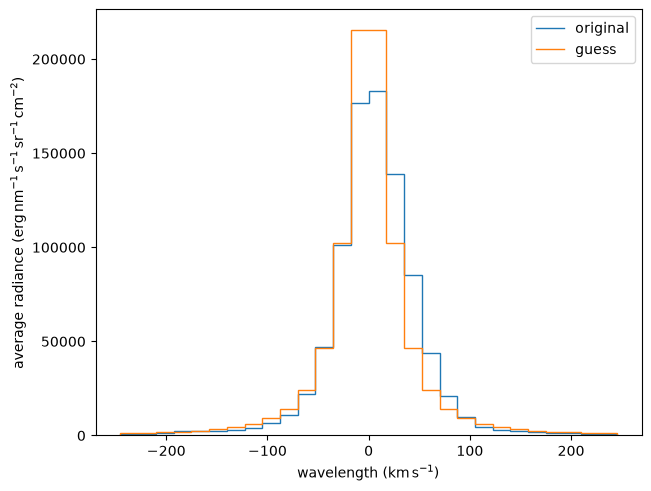

In [73]:
with astropy.visualization.quantity_support():
    fig, ax = plt.subplots(constrained_layout=True)
    na.plt.stairs(
        scene_degraded.inputs.velocity,
        scene_degraded.outputs.mean((scene.axis_detector_x, scene.axis_detector_y)),
        ax=ax,
        label="original",
        axis=scene.axis_wavelength,
    )
    na.plt.stairs(
        scene_degraded.inputs.velocity,
        guess.mean((scene.axis_detector_x, scene.axis_detector_y)),
        label="guess",
        axis=scene.axis_wavelength,
    )
    ax.set_xlabel(f"wavelength ({ax.get_xlabel()})")
    ax.set_ylabel(f"average radiance ({ax.get_ylabel()})");
    ax.legend()

In [74]:
%%time
inversion = mart(images, guess=guess, verbose=True)

i=0


merit: ScalarArray(
    ndarray=0.966008 ,
    shape={},
)


i=1


merit: ScalarArray(
    ndarray=0.7975459 ,
    shape={},
)


i=2


merit: ScalarArray(
    ndarray=0.70987934 ,
    shape={},
)


... (36 outputs left out)

i=21


merit: ScalarArray(
    ndarray=0.50367925 ,
    shape={},
)


i=22


merit: ScalarArray(
    ndarray=0.50272512 ,
    shape={},
)
CPU times: user 1min 37s, sys: 40.7 s, total: 2min 18s
Wall time: 2min 9s


In [75]:
axis_iter = inversion.inverter.axis_iteration

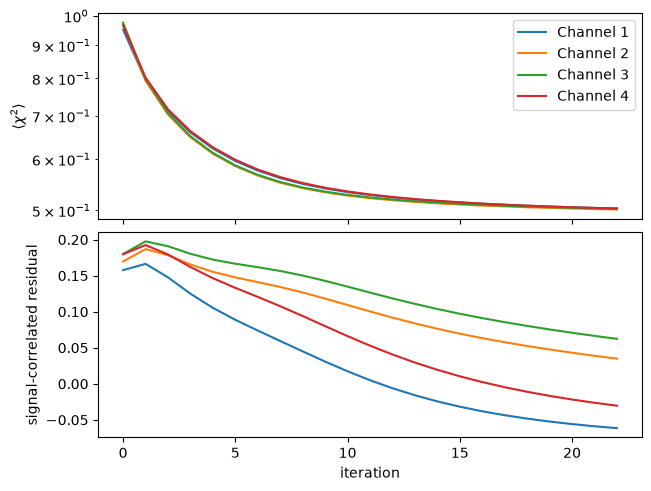

In [76]:
fig, ax = plt.subplots(
    nrows=2,
    sharex=True,
    constrained_layout=True,
)
na.plt.plot(
    inversion.iteration,
    inversion.mean_chi_squared,
    ax=ax[0],
    axis=axis_iter,
    label=channel,
)
na.plt.plot(
    inversion.iteration,
    inversion.correlation_residual,
    ax=ax[1],
    axis=axis_iter,
    label=channel,
)
ax[0].set_ylabel(r"$\langle \chi^2 \rangle$")
ax[1].set_xlabel("iteration")
ax[1].set_ylabel("signal-correlated residual")
ax[0].set_yscale("log")
ax[0].legend();

In [77]:
solution = inversion.solution

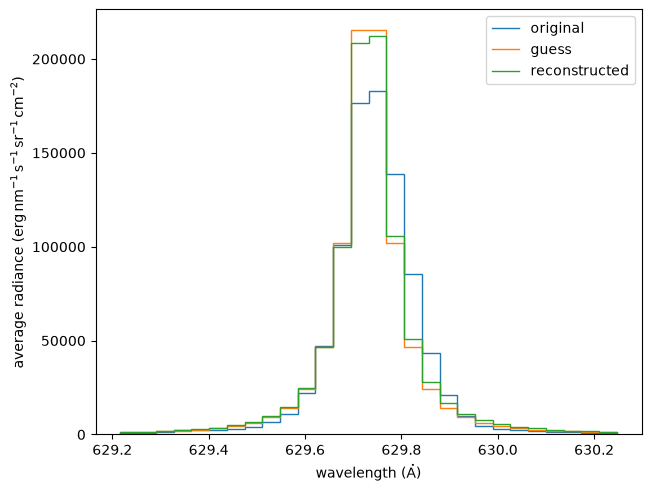

In [78]:
with astropy.visualization.quantity_support():
    fig, ax = plt.subplots(constrained_layout=True)
    na.plt.stairs(
        scene_degraded.inputs.wavelength,
        scene_degraded.outputs.mean((scene.axis_detector_x, scene.axis_detector_y)),
        ax=ax,
        label="original",
    )
    na.plt.stairs(
        scene_degraded.inputs.wavelength,
        guess.mean((scene.axis_detector_x, scene.axis_detector_y)),
        label="guess",
        axis=scene.axis_wavelength,
    )
    na.plt.stairs(
        solution.inputs.wavelength,
        solution.outputs.mean((scene.axis_detector_x, scene.axis_detector_y)),
        ax=ax,
        label="reconstructed",
    )
    ax.set_xlabel(f"wavelength ({ax.get_xlabel()})")
    # ax2.set_xlabel(f"wavelength ({ax2.get_xlabel()})")
    ax.set_ylabel(f"average radiance ({ax.get_ylabel()})")
    ax.legend()

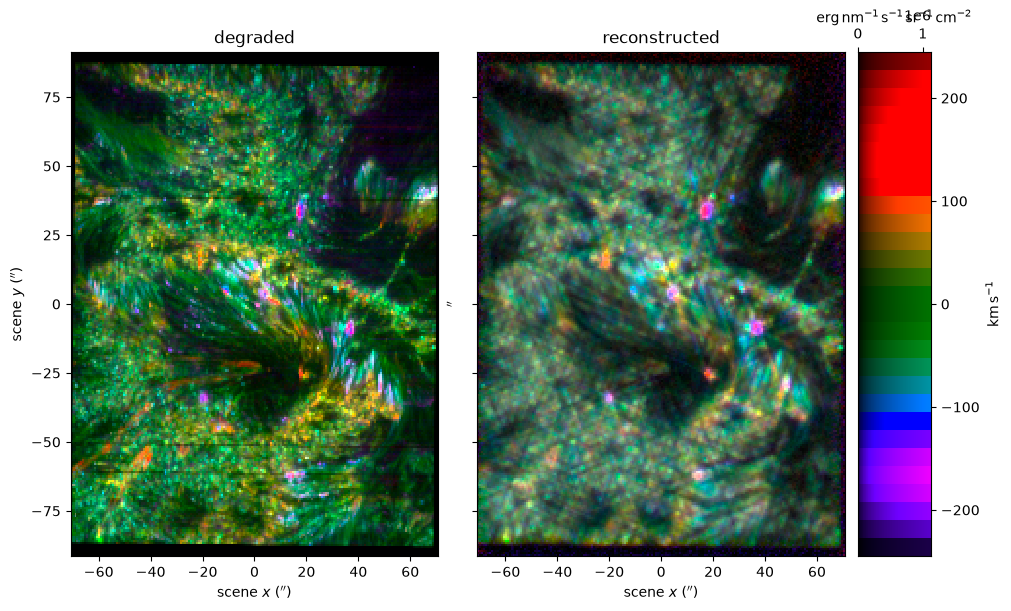

In [79]:
with astropy.visualization.quantity_support():
    fig, axs = plt.subplots(
        ncols=3,
        gridspec_kw=dict(width_ratios=[.5, .5, .1]),
        constrained_layout=True,
        figsize=(10, 6),
    )
    ax1, ax2, cax = axs
    ax2.set_yticklabels([])
    vmin = np.nanpercentile(
        a=scene_degraded.outputs,
        q=0.5,
        axis=(scene.axis_detector_x, scene.axis_detector_y),
    )
    vmax = np.nanpercentile(
        a=scene_degraded.outputs,
        q=99.5,
        axis=(scene.axis_detector_x, scene.axis_detector_y),
    )
    wavelength_min=-100 * u.km / u.s,
    wavelength_max=+100 * u.km / u.s,
    na.plt.rgbmesh(
        scene_degraded.inputs.velocity.cell_centers(scene.axis_wavelength),
        scene_degraded.inputs.position.x,
        scene_degraded.inputs.position.y,
        C=scene_degraded.outputs,
        axis_wavelength=scene.axis_wavelength,
        ax=ax1,
        vmin=vmin,
        vmax=vmax,
        wavelength_min=-250 * u.km / u.s,
        wavelength_max=+250 * u.km / u.s,
    )
    colorbar = na.plt.rgbmesh(
        scene_degraded.inputs.velocity.cell_centers(scene.axis_wavelength),
        scene_degraded.inputs.position.x,
        scene_degraded.inputs.position.y,
        C=solution.outputs,
        axis_wavelength=scene.axis_wavelength,
        ax=ax2,
        vmin=vmin,
        vmax=vmax,
        wavelength_min=-250 * u.km / u.s,
        wavelength_max=+250 * u.km / u.s,
    )
    na.plt.pcolormesh(
        C=colorbar,
        axis_rgb=scene.axis_wavelength,
        ax=cax,
    )
    ax1.set_title("degraded")
    ax2.set_title("reconstructed")
    unit_x = scene_degraded.inputs.position.x.unit
    unit_y = scene_degraded.inputs.position.y.unit
    ax1.set_xlabel(f"scene $x$ ({unit_x:latex_inline})")
    ax2.set_xlabel(f"scene $x$ ({unit_x:latex_inline})")
    ax1.set_ylabel(f"scene $y$ ({unit_y:latex_inline})")
    cax.xaxis.set_ticks_position("top")
    cax.xaxis.set_label_position("top")
    cax.yaxis.tick_right()
    cax.yaxis.set_label_position("right")

In [80]:
with astropy.visualization.quantity_support():
    fig, ax = plt.subplots(
        ncols=2,
        constrained_layout=True,
        sharex=True,
        sharey=True,
        figsize=(6, 5),
    )
    i = {scene.axis_detector_x: 100}
    vmax = scene_degraded.outputs.percentile(99.9).ndarray.value
    norm = matplotlib.colors.PowerNorm(gamma=0.5, vmin=0, vmax=vmax)
    na.plt.pcolormesh(
        scene_degraded.inputs.velocity[{scene.axis_detector_x: 0, scene.axis_detector_y: 0}],
        scene_degraded.inputs.position.y[i],
        C=scene_degraded.outputs[i].value,
        ax=ax[0],
        norm=norm,
    )
    ani = na.plt.pcolormovie(
        inversion.iteration,
        scene_degraded.inputs.velocity[{scene.axis_detector_x: 0, scene.axis_detector_y: 0}],
        inversion.solutions.inputs.position.y[i],
        C=inversion.solutions.outputs[i].to_value(scene_degraded.outputs.unit),
        ax=ax[1],
        axis_time=inversion.inverter.axis_iteration,
        norm=norm,
    )
    ax[0].set_title("original")
    ax[1].set_title("reconstruction")

result = ani.to_jshtml(fps=10)
result = IPython.display.HTML(result)

ani.save("mart-iris-spectra.gif", dpi=200, fps=30)

plt.close(ani._fig)

result

2026-11-14 16:41:02 - matplotlib.animation - INFO: Animation.save using <class 'matplotlib.animation.HTMLWriter'>


2026-11-14 16:41:07 - matplotlib.animation - WARNING: MovieWriter ffmpeg unavailable; using Pillow instead.


2026-11-14 16:41:07 - matplotlib.animation - INFO: Animation.save using <class 'matplotlib.animation.PillowWriter'>


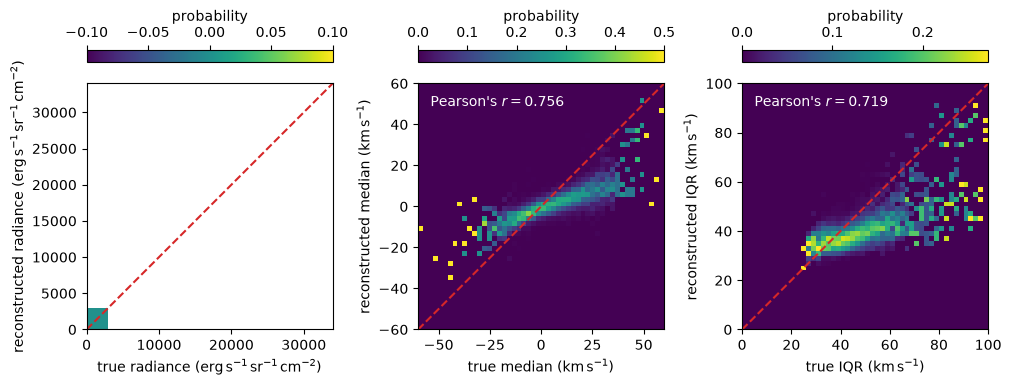

In [81]:
inversion.plot_moments(
    truth=scene_degraded, 
    axis=scene.axis_wavelength,
    range_radiance=[0, 3e3] * u.erg / u.s / u.sr / u.cm**2,
    range_median=[-60, 60] * u.km / u.s,
    range_iqr=[0, 100] * u.km / u.s,
    percentile_radiance=75,
);

In [82]:
%%time
predictions = instrument.image(solution, noise=False)

CPU times: user 1.42 s, sys: 999 ms, total: 2.42 s
Wall time: 2.25 s


In [83]:
residual = images - predictions

ScalarArray(
    ndarray=[(256.0, 768.0), (256.0, 768.0), (256.0, 768.0), (256.0, 768.0)],
    shape={'channel': 4},
)

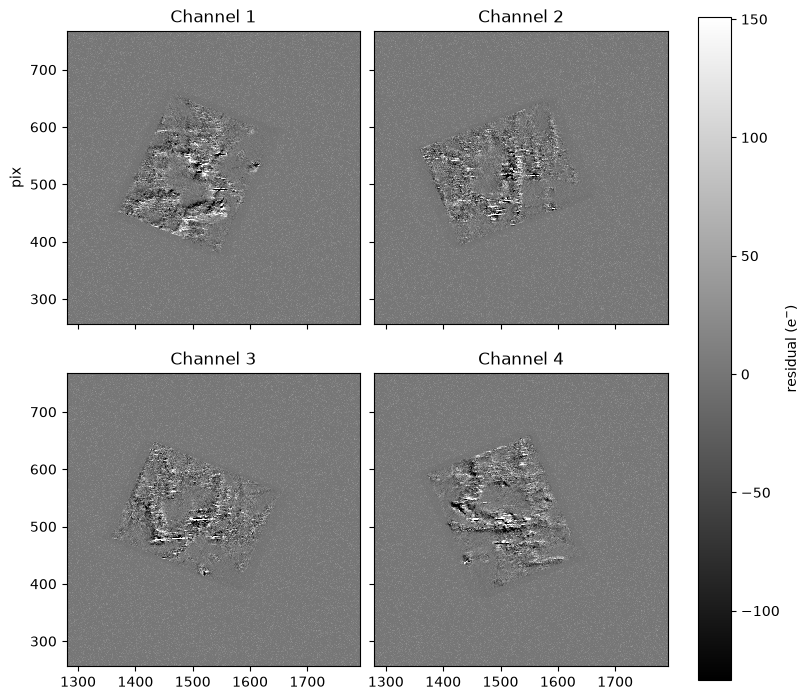

In [84]:
fig, ax = na.plt.subplots(
    axis_rows="rows",
    axis_cols="cols",
    nrows=2,
    ncols=2,
    constrained_layout=True,
    figsize=(8,7),
    sharex=True,
    sharey=True,
    origin="upper",
)
ax = ax.reshape(dict(channel=-1))
vmin = -100
vmax = +100
img = na.plt.pcolormesh(
    residual.inputs.position.x,
    residual.inputs.position.y,
    C=residual.outputs.value,
    ax=ax,
    vmin=residual.outputs.value.percentile(0.01).ndarray,
    vmax=residual.outputs.value.percentile(99.99).ndarray,
    cmap="gray",
)
na.plt.set_title
na.plt.set_aspect("equal", ax=ax)
plt.colorbar(
    ax=ax.ndarray,
    mappable=img.ndarray[0],
    label=f"residual ({residual.outputs.unit:latex_inline})",
);
na.plt.set_title(channel, ax=ax);
na.plt.set_xlim(1024 + 256, 1024 + 512 + 256, ax=ax)
na.plt.set_ylim(256, 512 + 256, ax=ax)

In [85]:
float(scipy.stats.spearmanr(predictions.outputs.ndarray.reshape(-1), residual.outputs.ndarray.reshape(-1)).statistic)

-0.073377779052802

In [86]:
float(scipy.stats.pearsonr(predictions.outputs.ndarray.reshape(-1), residual.outputs.ndarray.reshape(-1)).statistic)

0.002442801986684815

In [87]:
images_perfect = instrument.image(scene_degraded, noise=False)

In [88]:
inversion.inverter.correlation_residual(
    images.outputs,
    predictions.outputs,
).ptp()

ScalarArray(
    ndarray=0.12383628 ,
    shape={},
)

In [89]:
# with astropy.visualization.quantity_support():
#     fig, axs = plt.subplots(
#         ncols=3,
#         gridspec_kw=dict(width_ratios=[.5, .5, .1]),
#         constrained_layout=True,
#         figsize=(10, 6),
#     )
#     ax1, ax2, cax = axs
#     ax2.set_yticklabels([])
#     vmax = np.nanpercentile(
#         a=scene.outputs,
#         q=99.5,
        
#         axis=(scene.axis_detector_x, scene.axis_detector_y),
#     )

#     na.plt.rgbmesh(
#         C=scene_degraded,
#         axis_wavelength="wavelength",
#         ax=ax1,
#         vmin=0,
#         vmax=vmax,
#     )
#     label = "iteration = " + inversion.iteration.to_string_array("%d")
#     chisq_str = r"$\langle \chi^2 \rangle$"
#     label = label + f"\n{chisq_str} = " + inversion.mean_chi_squared.mean("channel").to_string_array("%.03f")
#     ani, colorbar = na.plt.rgbmovie(
#         label,
#         scene.velocity_doppler,
#         scene.inputs.position.x,
#         scene.inputs.position.y,
#         C=inversion.solutions.outputs,
#         axis_time=inversion.inverter.axis_iteration,
#         axis_wavelength="wavelength",
#         ax=ax2,
#         vmin=0,
#         vmax=vmax,
#     )
#     na.plt.pcolormesh(
#         C=colorbar,
#         axis_rgb="wavelength",
#         ax=cax,
#     )
#     ax1.set_title("original")
#     ax2.set_title("reconstructed")
#     unit_x = scene.inputs.position.x.unit
#     unit_y = scene.inputs.position.y.unit
#     ax1.set_xlabel(f"scene $x$ ({unit_x:latex_inline})")
#     ax2.set_xlabel(f"scene $x$ ({unit_x:latex_inline})")
#     ax1.set_ylabel(f"scene $y$ ({unit_y:latex_inline})")
#     cax.xaxis.set_ticks_position("top")
#     cax.xaxis.set_label_position("top")
#     cax.yaxis.tick_right()
#     cax.yaxis.set_label_position("right")

# result = ani.to_jshtml(fps=30)
# result = IPython.display.HTML(result)

# ani.save("mart-iris-rgb.mp4")

# plt.close(ani._fig)

# result

In [90]:
(images.outputs < 0).sum() / images.outputs.size

ScalarArray(ndarray=np.float64(0.0), shape={})

In [91]:
(guess < 0).sum()

ScalarArray(ndarray=np.int64(0), shape={})

 - mulitply counts by 10 to see how it changes the results
 - smooth the outputs before taking the residual (and computing the moments)
 - negative correlation coefficient implies that we went a little too far (crossed zero)

$d \chi = \frac{d' - d}{\sqrt{d}}$ contribution of the residual to the total chi square (SNR-weighted residual)